# Title : Analyzing Weather Data from OpenWeatherMap API

In [1]:
# Import libraries required for API requests and data processing
import requests 
import pandas as pd 
import datetime

In [2]:
# Set your OpenWeatherMap API key
api_key = 'fb365aa6104829b44455572365ff3b4e' 

In [3]:
# Set the location for which you want to retrieve weather data 
lat = 18.184135
lon = 74.610764

In [4]:
# https://openweathermap.org/api/one-call-3
# how	How to use api call 
# Construct the API URL
api_url = f"http://api.openweathermap.org/data/2.5/forecast?lat={lat}&lon={lon}&appid={api_key}"

In [5]:
# Send a GET request to the API 
response = requests.get(api_url)
weather_data = response.json()
weather_data.keys()
len(weather_data['list'])
weather_data['list'][0]['weather'][0]['description']

'broken clouds'

In [6]:
# Getting the data from dictionary and taking into one variable 
# Extract relevant weather attributes using list comprehension
temperatures = [item['main']['temp'] for item in weather_data['list']] 

# It will extract all values (40) and putting into one variable
timestamps = [pd.to_datetime(item['dt'], unit='s') for item in weather_data['list']]
temperature = [item['main']['temp'] for item in weather_data['list']]
humidity = [item['main']['humidity'] for item in weather_data['list']]
wind_speed = [item['wind']['speed'] for item in weather_data['list']]
weather_description = [item['weather'][0]['description'] for item in weather_data['list']]

In [7]:
# Create a pandas DataFrame with the extracted weather data
weather_df = pd.DataFrame({'Timestamp': timestamps, 
                           'Temperature': temperatures, 
                           'humidity': humidity, 
                           'wind_speed':wind_speed,
                           'weather_description': weather_description})

In [8]:
# Set the Timestamp column as the DataFrame's index
weather_df.set_index('Timestamp', inplace=True)
max_temp = weather_df['Temperature'].max()
print(f"Maximum Temperature - {max_temp}")
min_temp = weather_df['Temperature'].min()
print(f"Minimum Temperature - {min_temp}")

Maximum Temperature - 307.35
Minimum Temperature - 296.84


In [9]:
# Clean and preprocess the data # Handling missing values
weather_df.fillna(0, inplace=True) # Replace missing values with 0 or appropriate value

,Temperature,humidity,wind_speed,weather_description
Timestamp,,,,
2026-10-16 09:00:00,306.93,27,2.15,broken clouds
2026-10-16 12:00:00,306.37,27,2.04,broken clouds
2026-10-16 15:00:00,303.54,29,4.00,overcast clouds
2026-10-16 18:00:00,299.97,33,2.92,overcast clouds
2026-10-16 21:00:00,297.95,41,1.90,overcast clouds
2026-10-17 00:00:00,297.05,49,2.90,broken clouds
2026-10-17 03:00:00,300.86,40,1.84,scattered clouds
2026-10-17 06:00:00,305.15,29,2.15,scattered clouds
2026-10-17 09:00:00,307.19,25,2.70,clear sky


In [10]:
# Handling inconsistent format (if applicable)
weather_df['Temperature'] = weather_df['Temperature'].apply(lambda x: x - 273.15 if isinstance(x, float)else x)

In [11]:
# Convert temperature from Kelvin to Celsius
# Print the cleaned and preprocessed data print(weather_df)
print(weather_df)

                     Temperature  humidity  wind_speed weather_description
Timestamp                                                                 
2026-10-16 09:00:00        33.78        27        2.15       broken clouds
2026-10-16 12:00:00        33.22        27        2.04       broken clouds
2026-10-16 15:00:00        30.39        29        4.00     overcast clouds
2026-10-16 18:00:00        26.82        33        2.92     overcast clouds
2026-10-16 21:00:00        24.80        41        1.90     overcast clouds
2026-10-17 00:00:00        23.90        49        2.90       broken clouds
2026-10-17 03:00:00        27.71        40        1.84    scattered clouds
2026-10-17 06:00:00        32.00        29        2.15    scattered clouds
2026-10-17 09:00:00        34.04        25        2.70           clear sky
2026-10-17 12:00:00        33.09        25        2.94           clear sky
2026-10-17 15:00:00        29.98        27        5.31       broken clouds
2026-10-17 18:00:00      

In [12]:
# Calculate daily average temperature, humidity, and wind speed
import matplotlib.pyplot as plt
daily_mean_temp = weather_df['Temperature'].resample('D').mean()
daily_mean_humidity = weather_df['humidity'].resample('D').mean()
daily_mean_wind_speed = weather_df['wind_speed'].resample('D').mean()

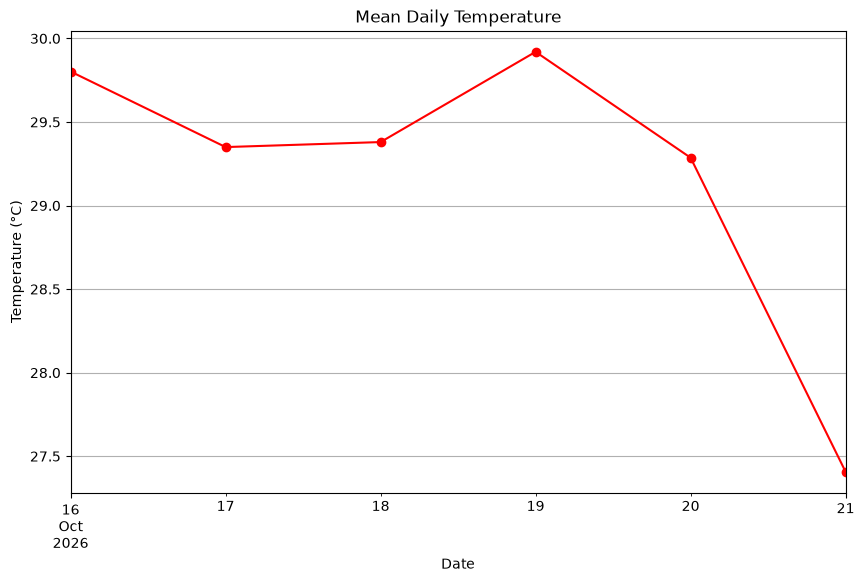

In [13]:
# Plot the mean daily temperature over time (Line plot)
plt.figure(figsize=(10, 6))
daily_mean_temp.plot(color='red', linestyle='-', marker='o')
plt.title('Mean Daily Temperature')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.grid(True)
plt.show()

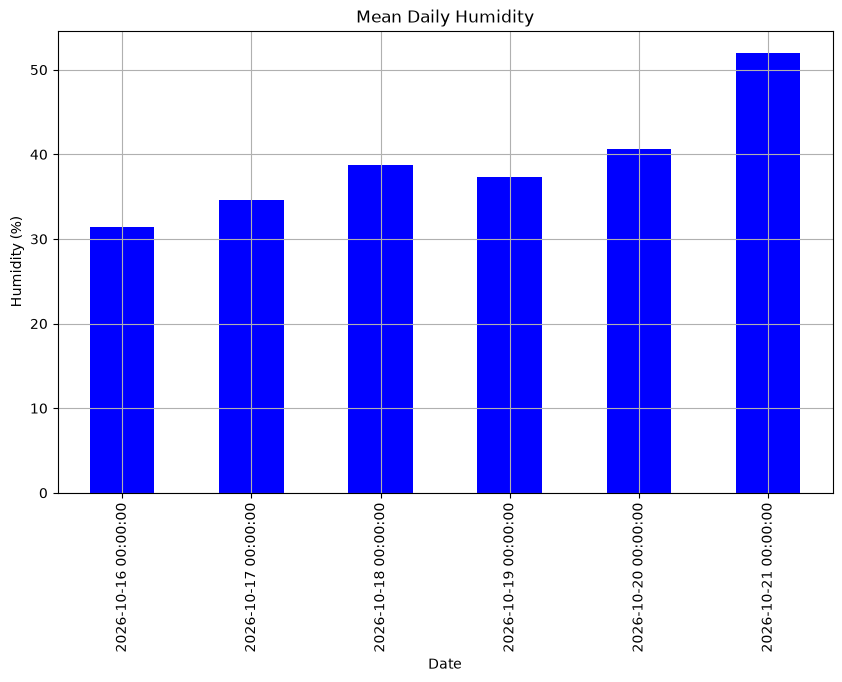

In [14]:
# Plot the mean daily humidity over time (Bar plot)
plt.figure(figsize=(10, 6))
daily_mean_humidity.plot(kind='bar', color='blue')
plt.title('Mean Daily Humidity')
plt.xlabel('Date')
plt.ylabel('Humidity (%)')
plt.grid(True)
plt.show()

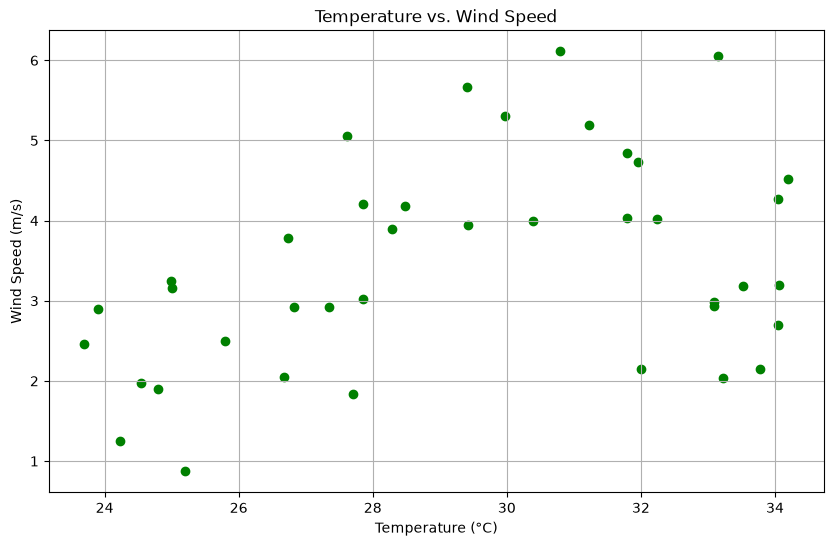

In [15]:
# Plot the relationship between temperature and wind speed (Scatter plot)
plt.figure(figsize=(10, 6))
plt.scatter(weather_df['Temperature'], weather_df['wind_speed'], color='green')
plt.title('Temperature vs. Wind Speed')
plt.xlabel('Temperature (°C)')
plt.ylabel('Wind Speed (m/s)')
plt.grid(True)
plt.show()

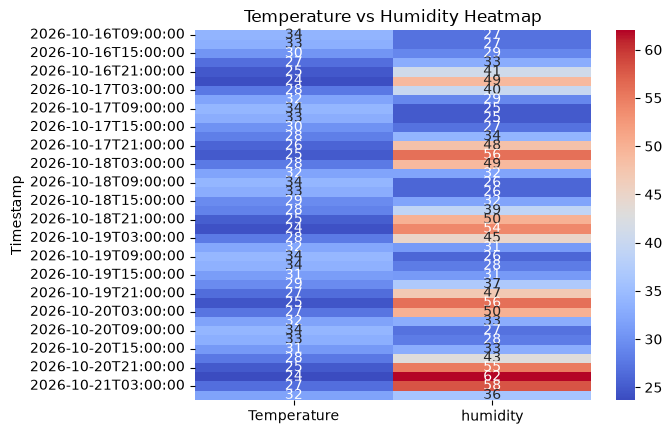

In [16]:
# Heatmap
import seaborn as sns
heatmap_data = weather_df[['Temperature', 'humidity']]
sns.heatmap(heatmap_data, annot=True, cmap='coolwarm')
plt.title('Temperature vs Humidity Heatmap')
plt.show()

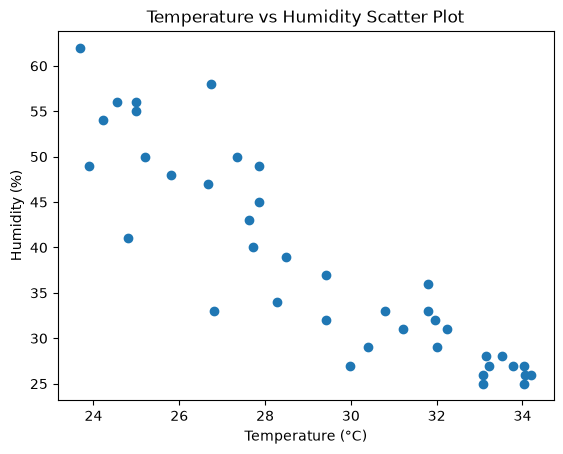

In [17]:
# Create a scatter plot to visualize the relationship between temperature and humidity
plt.scatter(weather_df['Temperature'], weather_df['humidity'])
plt.xlabel('Temperature (°C)')
plt.ylabel('Humidity (%)')
plt.title('Temperature vs Humidity Scatter Plot')
plt.show()

In [ ]:
# Empty code cell reserved for additional work
